# Cheating Tracking System

## 1. Install

In [1]:
!pip -q install ultralytics roboflow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 2. Configuration

In [2]:
import json, os, random, shutil, time, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
import cv2

from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

warnings.filterwarnings("ignore")

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---- Roboflow dataset (your private project: exam-cheating-dataset) ----
RF_WORKSPACE = "badr-zahran-exsvb"
RF_PROJECT = "exam-cheating-dataset-bhwqb"
RF_VERSION = 1            # open the dataset page on Roboflow Universe and use the version you want
RF_FORMAT = "yolov8"      # same label format for YOLOv8 / YOLO11

# ---- Model (the brief recommends YOLOv8 / YOLOv11) ----
MODEL = "yolov8s.pt"      # or "yolo11s.pt"
IMGSZ = 640               # raise to 960 if the objects (e.g. phones) are very small
BATCH = 16
EPOCHS = 80
PATIENCE = 20

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./work")
RUNS = WORK / "runs"
RUNS.mkdir(parents=True, exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else "cpu"


print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Device: Tesla T4


## 3. Import the Roboflow dataset

In [4]:
# get roboflow api key from kaggle secrets
API_KEY = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")

# connect to roboflow
rf = Roboflow(api_key=API_KEY)

project = rf.workspace(RF_WORKSPACE).project(RF_PROJECT)

dataset = project.version(RF_VERSION).download(
    RF_FORMAT,
    location=str(WORK / "dataset")
)

DATA_DIR = Path(dataset.location)
DATA_YAML = DATA_DIR / "data.yaml"

print("Dataset folder:", DATA_DIR)
print("Dataset YAML:", DATA_YAML)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/dataset in yolov8:: 100%|██████████| 10899/10899 [00:01<00:00, 10221.96it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dataset folder: /kaggle/working/dataset
Dataset YAML: /kaggle/working/dataset/data.yaml


In [5]:
# Roboflow's data.yaml may use relative paths. Rewrite it with absolute ones so Ultralytics finds every split.
cfg = yaml.safe_load(open(DATA_YAML))

for split, folder in [("train", "train"), ("val", "valid"), ("test", "test")]:
    if (DATA_DIR / folder / "images").exists():
        cfg[split] = str(DATA_DIR / folder / "images")
    else:
        cfg.pop(split, None)

cfg["path"] = str(DATA_DIR)

yaml.safe_dump(cfg, open(DATA_YAML, "w"))

CLASS_NAMES = cfg["names"] if isinstance(cfg["names"], list) else [cfg["names"][k] for k in sorted(cfg["names"])]
print("Classes (%d): %s" % (len(CLASS_NAMES), CLASS_NAMES))

TEST_SPLIT = "test" if "test" in cfg else "val"
print("Evaluation split:", TEST_SPLIT)

Classes (3): ['cheating', 'normal', 'suspected cheating']
Evaluation split: test


## 4. Dataset overview (images and boxes per split / class)

,split,images,cheating,normal,suspected cheating
0,train,3816,2823,3907,4755
1,valid,1085,803,987,1189
2,test,546,414,549,717


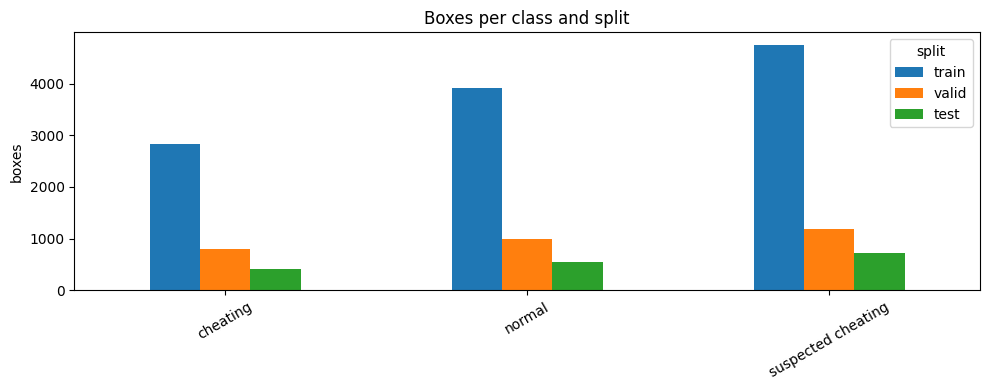

overlap train / valid: 158 source images
overlap train / test: 113 source images
overlap valid / test: 82 source images


In [6]:
rows = []

for folder in ["train", "valid", "test"]:
    img_dir, lbl_dir = DATA_DIR / folder / "images", DATA_DIR / folder / "labels"
    
    if not img_dir.exists():
        continue
    n_img = len(list(img_dir.glob("*")))
    counts = np.zeros(len(CLASS_NAMES), dtype=int)
    
    for f in lbl_dir.glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                counts[int(line.split()[0])] += 1
    rows.append({"split": folder, "images": n_img, **dict(zip(CLASS_NAMES, counts))})

overview = pd.DataFrame(rows)
display(overview)

per_class = overview.drop(columns=["images"]).set_index("split").T
per_class.plot(kind="bar", figsize=(10, 4))
plt.title("Boxes per class and split")
plt.ylabel("boxes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(WORK / "dataset_boxes_per_class.png", dpi=150)
plt.show()

# sanity check: the same source image must not appear in two splits (data leakage)
def src(p):   # Roboflow names files  <original>_jpg.rf.<hash>.jpg
    return p.name.split(".rf.")[0]

seen = {f: {src(p) for p in (DATA_DIR / f / "images").glob("*")} for f in ["train", "valid", "test"] if (DATA_DIR / f / "images").exists()}

names = list(seen)

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        print(f"overlap {names[i]} / {names[j]}: {len(seen[names[i]] & seen[names[j]])} source images")

### 4b) Fix data leakage: re-split by scene
The overlap check above found the same images in train / valid / test, which inflates the test scores. This cell groups duplicate and near-duplicate images (perceptual hash, mirrored copies included), assigns each group to a single split (70/20/10), and points `DATA_DIR` / `DATA_YAML` to the clean copy. It must print **0** cross-split pairs. Run it before training. Consecutive video frames that are visually different can still be neighbours; raise `HASH_MAX_DIST` to merge more of them.

In [7]:
# Re-split the dataset so duplicate / near-duplicate images never sit in different splits (removes leakage).
# Images are grouped by a perceptual hash (dHash, also compared mirrored); each group goes to ONE split.
CLEAN = WORK / "dataset_clean"
HASH_MAX_DIST = 6                                   # max differing bits (of 64) to treat two images as the same scene
SPLIT_FRACS = {"train": 0.70, "valid": 0.20, "test": 0.10}

def dhash(img_bgr_gray):
    small = cv2.resize(img_bgr_gray, (9, 8), interpolation=cv2.INTER_AREA)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)

items = []                                          # (orig_split, image_path, label_path)
for sp in ["train", "valid", "test"]:
    idir = DATA_DIR / sp / "images"
    if idir.exists():
        for p in sorted(idir.glob("*")):
            items.append((sp, p, DATA_DIR / sp / "labels" / (p.stem + ".txt")))

h, hf = [], []
for _, p, _ in items:
    g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    if g is None:
        g = np.zeros((8, 9), np.uint8)
    h.append(dhash(g)); hf.append(dhash(cv2.flip(g, 1)))
h = np.array(h, dtype=np.uint64); hf = np.array(hf, dtype=np.uint64)

POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def hamming(a, b):                                   # a: (k,) uint64, b: (n,) uint64 -> (k, n)
    x = np.bitwise_xor(a[:, None], b[None, :])
    return POP[x.view(np.uint8).reshape(x.shape + (8,))].sum(-1)

parent = list(range(len(items)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for s in range(0, len(items), 256):
    e = min(s + 256, len(items))
    d = np.minimum(hamming(h[s:e], h), hamming(h[s:e], hf))
    for i, j in zip(*np.where(d <= HASH_MAX_DIST)):
        i += s
        if i != j:
            parent[find(i)] = find(int(j))

groups = defaultdict(list)
for i in range(len(items)):
    groups[find(i)].append(i)
sizes = sorted((len(v) for v in groups.values()), reverse=True)
print(f"{len(items)} images -> {len(groups)} unique scenes (largest group: {sizes[0]} images)")

# assign whole groups to splits, keeping the target ratios
rng = random.Random(SEED)
order = list(groups.values()); rng.shuffle(order)
order.sort(key=len, reverse=True)                    # big groups first so the ratios stay balanced
assigned = {s: [] for s in SPLIT_FRACS}
for g in order:
    sp = max(SPLIT_FRACS, key=lambda s: SPLIT_FRACS[s] * len(items) - len(assigned[s]))
    assigned[sp].extend(g)

if CLEAN.exists():
    shutil.rmtree(CLEAN)
for sp, idxs in assigned.items():
    (CLEAN / sp / "images").mkdir(parents=True); (CLEAN / sp / "labels").mkdir(parents=True)
    for i in idxs:
        osp, ip, lp = items[i]
        stem = f"{osp}_{ip.stem}"                    # prefix avoids filename clashes between the old splits
        shutil.copy(ip, CLEAN / sp / "images" / (stem + ip.suffix))
        if lp.exists():
            shutil.copy(lp, CLEAN / sp / "labels" / (stem + ".txt"))

new_cfg = {"path": str(CLEAN), "train": str(CLEAN / "train" / "images"), "val": str(CLEAN / "valid" / "images"),
           "test": str(CLEAN / "test" / "images"), "nc": len(CLASS_NAMES), "names": CLASS_NAMES}
yaml.safe_dump(new_cfg, open(CLEAN / "data.yaml", "w"))
DATA_DIR, DATA_YAML, TEST_SPLIT = CLEAN, CLEAN / "data.yaml", "test"

# verify: no pair of images from different splits is closer than the threshold
split_of = np.empty(len(items), dtype=object)
for sp, idxs in assigned.items():
    split_of[idxs] = sp
leaks = 0
for s in range(0, len(items), 256):
    e = min(s + 256, len(items))
    d = np.minimum(hamming(h[s:e], h), hamming(h[s:e], hf))
    different = split_of[s:e, None] != split_of[None, :]
    leaks += int(((d <= HASH_MAX_DIST) & different).sum())
print("Cross-split near-duplicate pairs after re-split:", leaks, "(must be 0)")

rows = []
for sp in ["train", "valid", "test"]:
    counts = np.zeros(len(CLASS_NAMES), dtype=int)
    for f in (CLEAN / sp / "labels").glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                counts[int(line.split()[0])] += 1
    rows.append({"split": sp, "images": len(list((CLEAN / sp / "images").glob("*"))), **dict(zip(CLASS_NAMES, counts))})
display(pd.DataFrame(rows))


5447 images -> 2602 unique scenes (largest group: 315 images)
Cross-split near-duplicate pairs after re-split: 0 (must be 0)


,split,images,cheating,normal,suspected cheating
0,train,3813,3229,3598,4377
1,valid,1089,634,1242,1384
2,test,545,177,603,900


### Sample images with their boxes

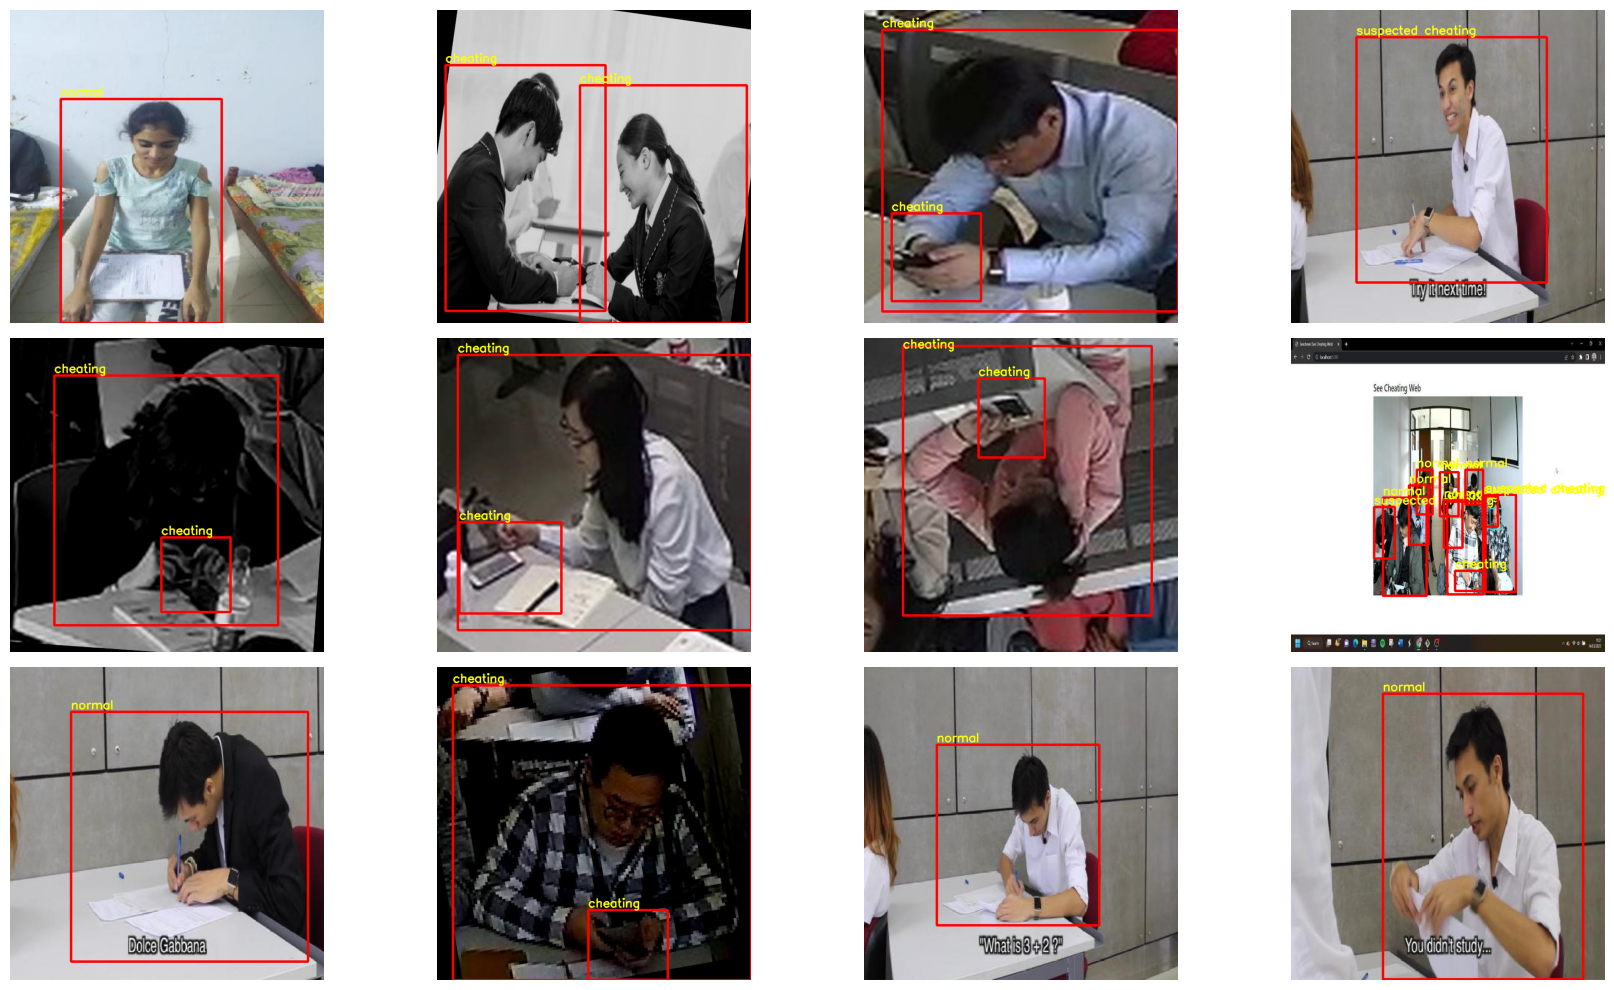

In [8]:
def draw_sample(img_path, lbl_path):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    
    if lbl_path.exists():
        for ln in lbl_path.read_text().splitlines():
            if not ln.strip():
                continue
            
            c, x, y, bw, bh = ln.split()[:5]
            x, y, bw, bh = float(x) * w, float(y) * h, float(bw) * w, float(bh) * h
            p1, p2 = (int(x - bw / 2), int(y - bh / 2)), (int(x + bw / 2), int(y + bh / 2))
            
            cv2.rectangle(img, p1, p2, (255, 0, 0), 3)
            
            cv2.putText(img, CLASS_NAMES[int(c)], (p1[0], max(20, p1[1] - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 0), 2)
    return img

train_imgs = sorted((DATA_DIR / "train" / "images").glob("*"))
sample = random.sample(train_imgs, min(12, len(train_imgs)))

fig, axes = plt.subplots(3, 4, figsize=(18, 10))

for ax, p in zip(axes.ravel(), sample):
    ax.imshow(draw_sample(p, DATA_DIR / "train" / "labels" / (p.stem + ".txt")))
    ax.axis("off")

for ax in axes.ravel()[len(sample):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Which classes count as cheating?
This dataset has 3 classes: `cheating`, `normal`, `suspected cheating`.
- `cheating` and `suspected cheating` raise alerts (red box). `normal` never does.
- `suspected cheating` is the largest and most ambiguous class, so the local app waits **more consecutive frames**
  before alerting on it (`SUSPECTED_FRAMES`), which reduces false alarms. Check the confusion matrix after training.

In [9]:
CHEATING_CLASSES = ["cheating", "suspected cheating"]      # NOT "normal"
SUSPECTED_FRAMES = 15      # consecutive processed frames needed for "suspected cheating" (default for cheating: 10)

assert all(c in CLASS_NAMES for c in CHEATING_CLASSES), f"Unknown class in CHEATING_CLASSES. Valid: {CLASS_NAMES}"

def behavior_label(name):
    """Text stored in the database / shown in the notification, e.g. 'Cheating detected'."""
    n = name.lower()
    if any(k in n for k in ("phone", "mobile", "cell")):
        return "Phone detected"
    return name.replace("_", " ").replace("-", " ").strip().capitalize() + " detected"

BEHAVIOR_LABELS = {c: behavior_label(c) for c in CHEATING_CLASSES}
BEHAVIOR_RULES = {BEHAVIOR_LABELS[c]: {"consecutive_frames": SUSPECTED_FRAMES} for c in CHEATING_CLASSES if "suspect" in c.lower()}

print(BEHAVIOR_LABELS)
print(BEHAVIOR_RULES)

{'cheating': 'Cheating detected', 'suspected cheating': 'Suspected cheating detected'}
{'Suspected cheating detected': {'consecutive_frames': 15}}


### Box sizes per class (information)
The annotations mix **whole-student boxes** and **small boxes** (hands / paper). The local app handles both
automatically: a box that overlaps a tracked student (IoU) is attributed to that student; a small box is attributed
to the student whose wrist is closest. Nothing to configure unless a class is always one kind: then set
`CLASS_KIND_OVERRIDE = {"class name": "person"}` (or `"object"`).

In [10]:
import collections

heights = collections.defaultdict(list)

for f in (DATA_DIR / "train" / "labels").glob("*.txt"):
    for line in f.read_text().splitlines():
        parts = line.split()
        if len(parts) >= 5:
            heights[int(parts[0])].append(float(parts[4]))

CLASS_KIND_OVERRIDE = {}          # leave empty = automatic (recommended)

for i, n in enumerate(CLASS_NAMES):
    h = np.array(heights[i]) if heights[i] else np.array([0.0])
    
    print(f"{n:20s} boxes={len(heights[i]):6d}  box height  median={np.median(h):.2f}  "
          f"share of small boxes (<0.25)={np.mean(h < 0.25):.0%}")

cheating             boxes=  3229  box height  median=0.31  share of small boxes (<0.25)=38%
normal               boxes=  3598  box height  median=0.28  share of small boxes (<0.25)=46%
suspected cheating   boxes=  4377  box height  median=0.24  share of small boxes (<0.25)=51%


## 6. Train

In [11]:
from ultralytics import YOLO

t0 = time.time()
model = YOLO(MODEL)

model.train(
    data=str(DATA_YAML), epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
    project=str(RUNS), name="train", exist_ok=True, seed=SEED, plots=True,
    fliplr=0.5, hsv_v=0.4, degrees=5, scale=0.5, mosaic=1.0,
)

BEST = RUNS / "train" / "weights" / "best.pt"

print("Training time (min):", round((time.time() - t0) / 60, 1), "| best:", BEST)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_clean/data.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False

## 7. Evaluate on the test split

In [12]:
metrics = YOLO(str(BEST)).val(
    data=str(DATA_YAML), split=TEST_SPLIT, imgsz=IMGSZ, device=DEVICE, plots=True,
    project=str(RUNS), name="eval", exist_ok=True,
)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1274.2±417.0 MB/s, size: 45.9 KB)
val: Scanning /kaggle/working/dataset_clean/test/labels... 545 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 545/545 1.2Kit/s 0.5s
val: New cache created: /kaggle/working/dataset_clean/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 3.9it/s 8.9s
                   all        545       1680      0.643      0.669      0.661      0.377
              cheating         84        177      0.742      0.701      0.717       0.46
                normal        286        603      0.573      0.584      0.599      0.332
    suspected cheating        351        900      0.612      0.723      0.667      0.338
Speed: 1.1ms preprocess, 10.7ms inference, 0.0ms loss, 1.0

In [13]:
summary = {
    "split": TEST_SPLIT,
    "precision": round(float(metrics.box.mp), 4), "recall": round(float(metrics.box.mr), 4),
    "mAP50": round(float(metrics.box.map50), 4), "mAP50-95": round(float(metrics.box.map), 4),
}

print(summary)

{'split': 'test', 'precision': 0.6425, 'recall': 0.6693, 'mAP50': 0.6611, 'mAP50-95': 0.3766}


In [14]:
per_cls = pd.DataFrame({
    "class": [CLASS_NAMES[i] for i in metrics.box.ap_class_index],
    "AP50": np.round(metrics.box.ap50, 3),
    "AP50-95": np.round(metrics.box.ap, 3),
})

display(per_cls)

,class,AP50,AP50-95
0,cheating,0.717,0.460
1,normal,0.599,0.332
2,suspected cheating,0.667,0.338


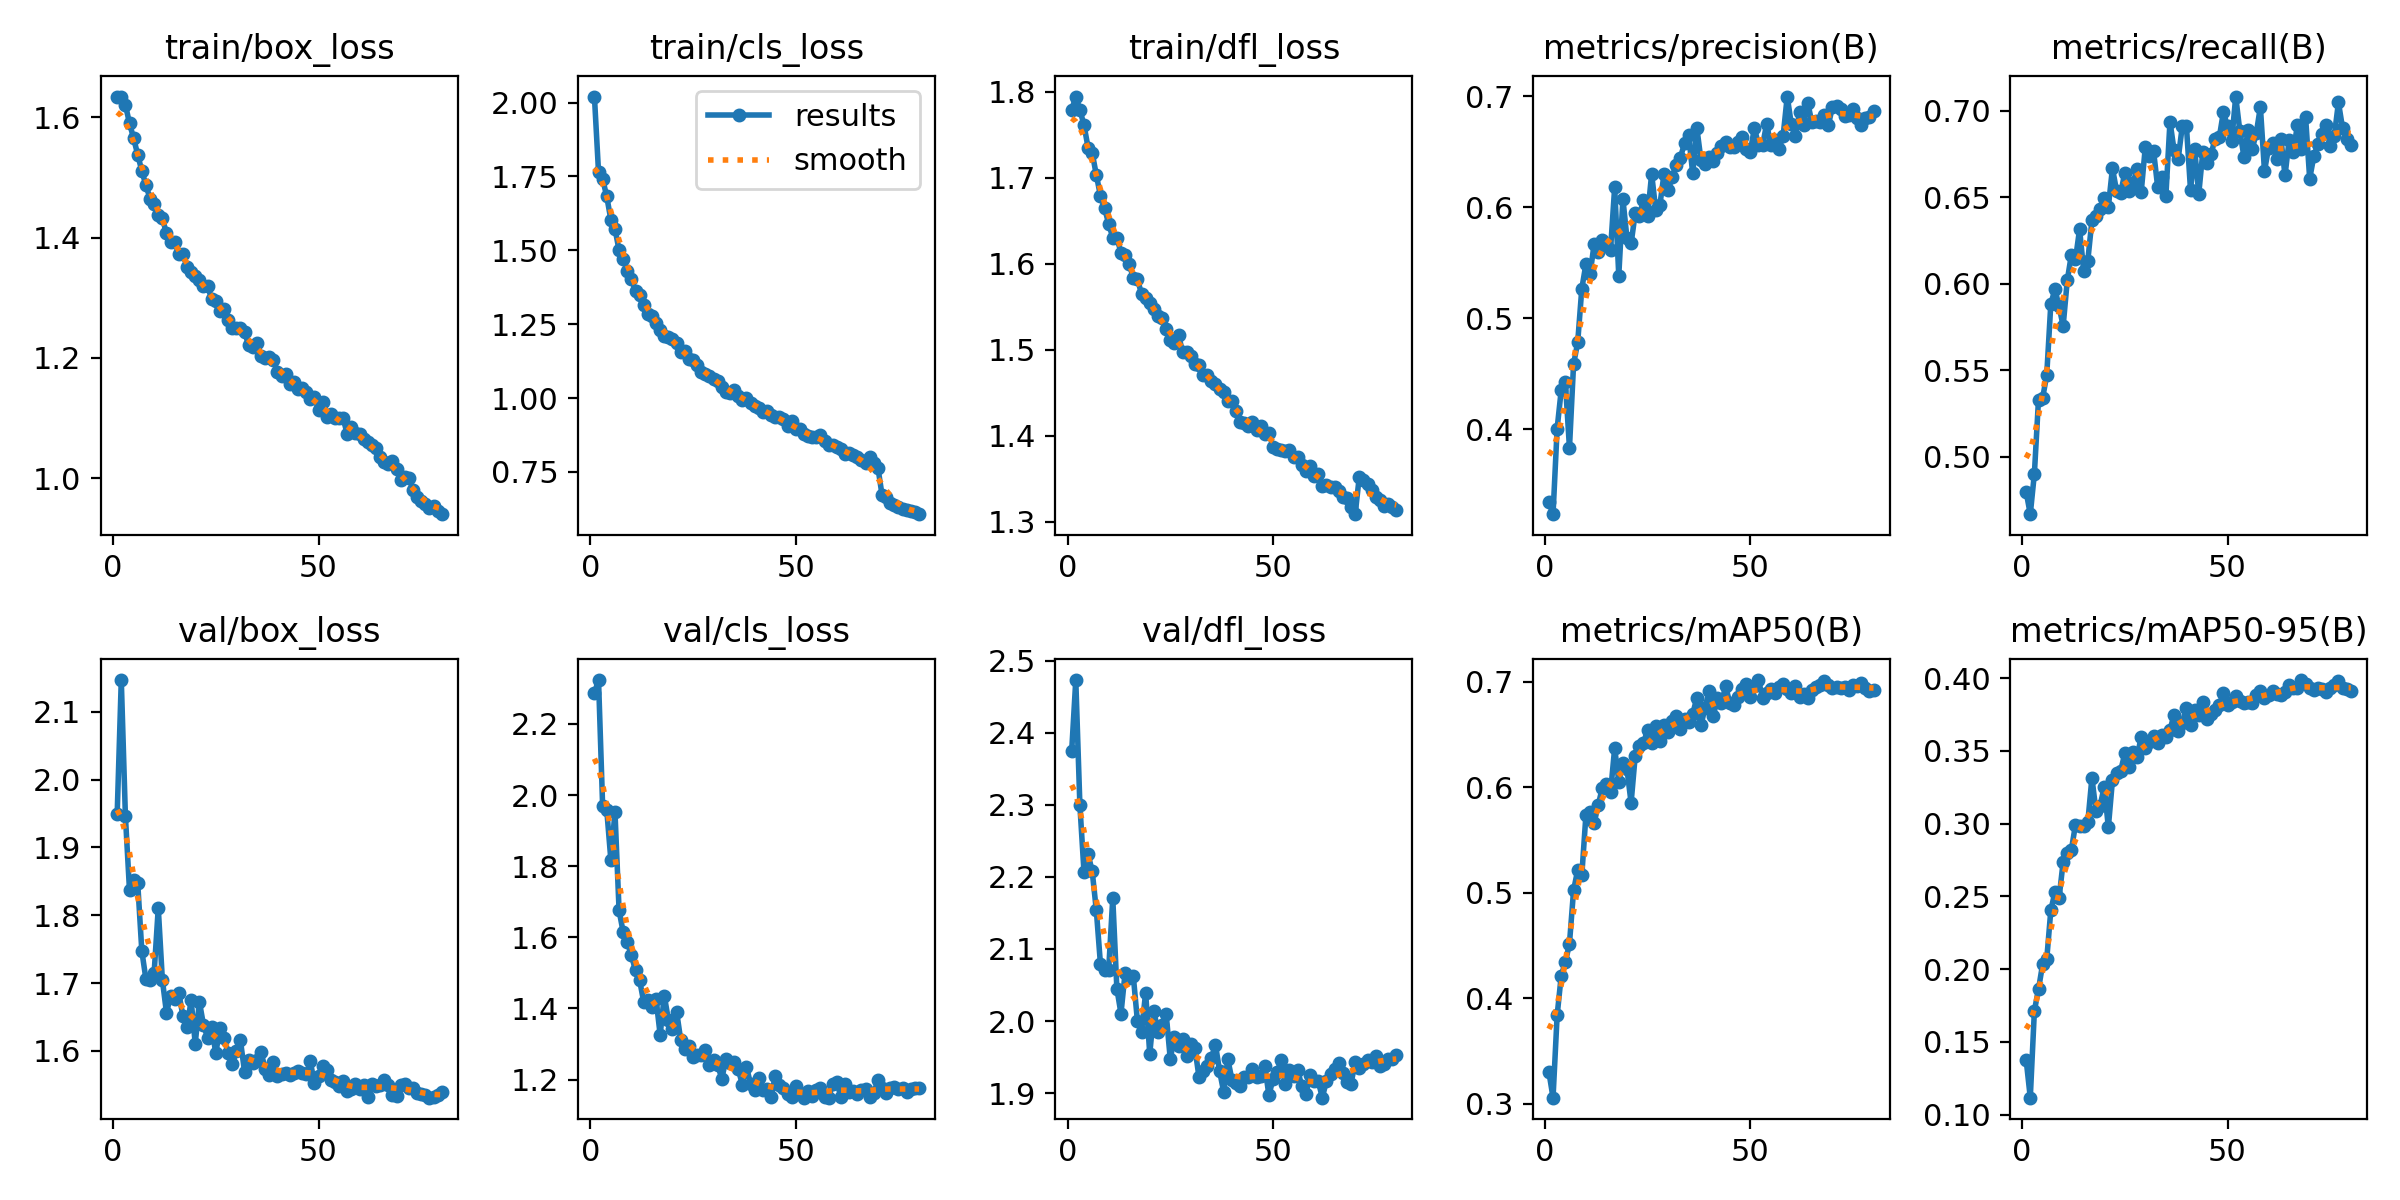

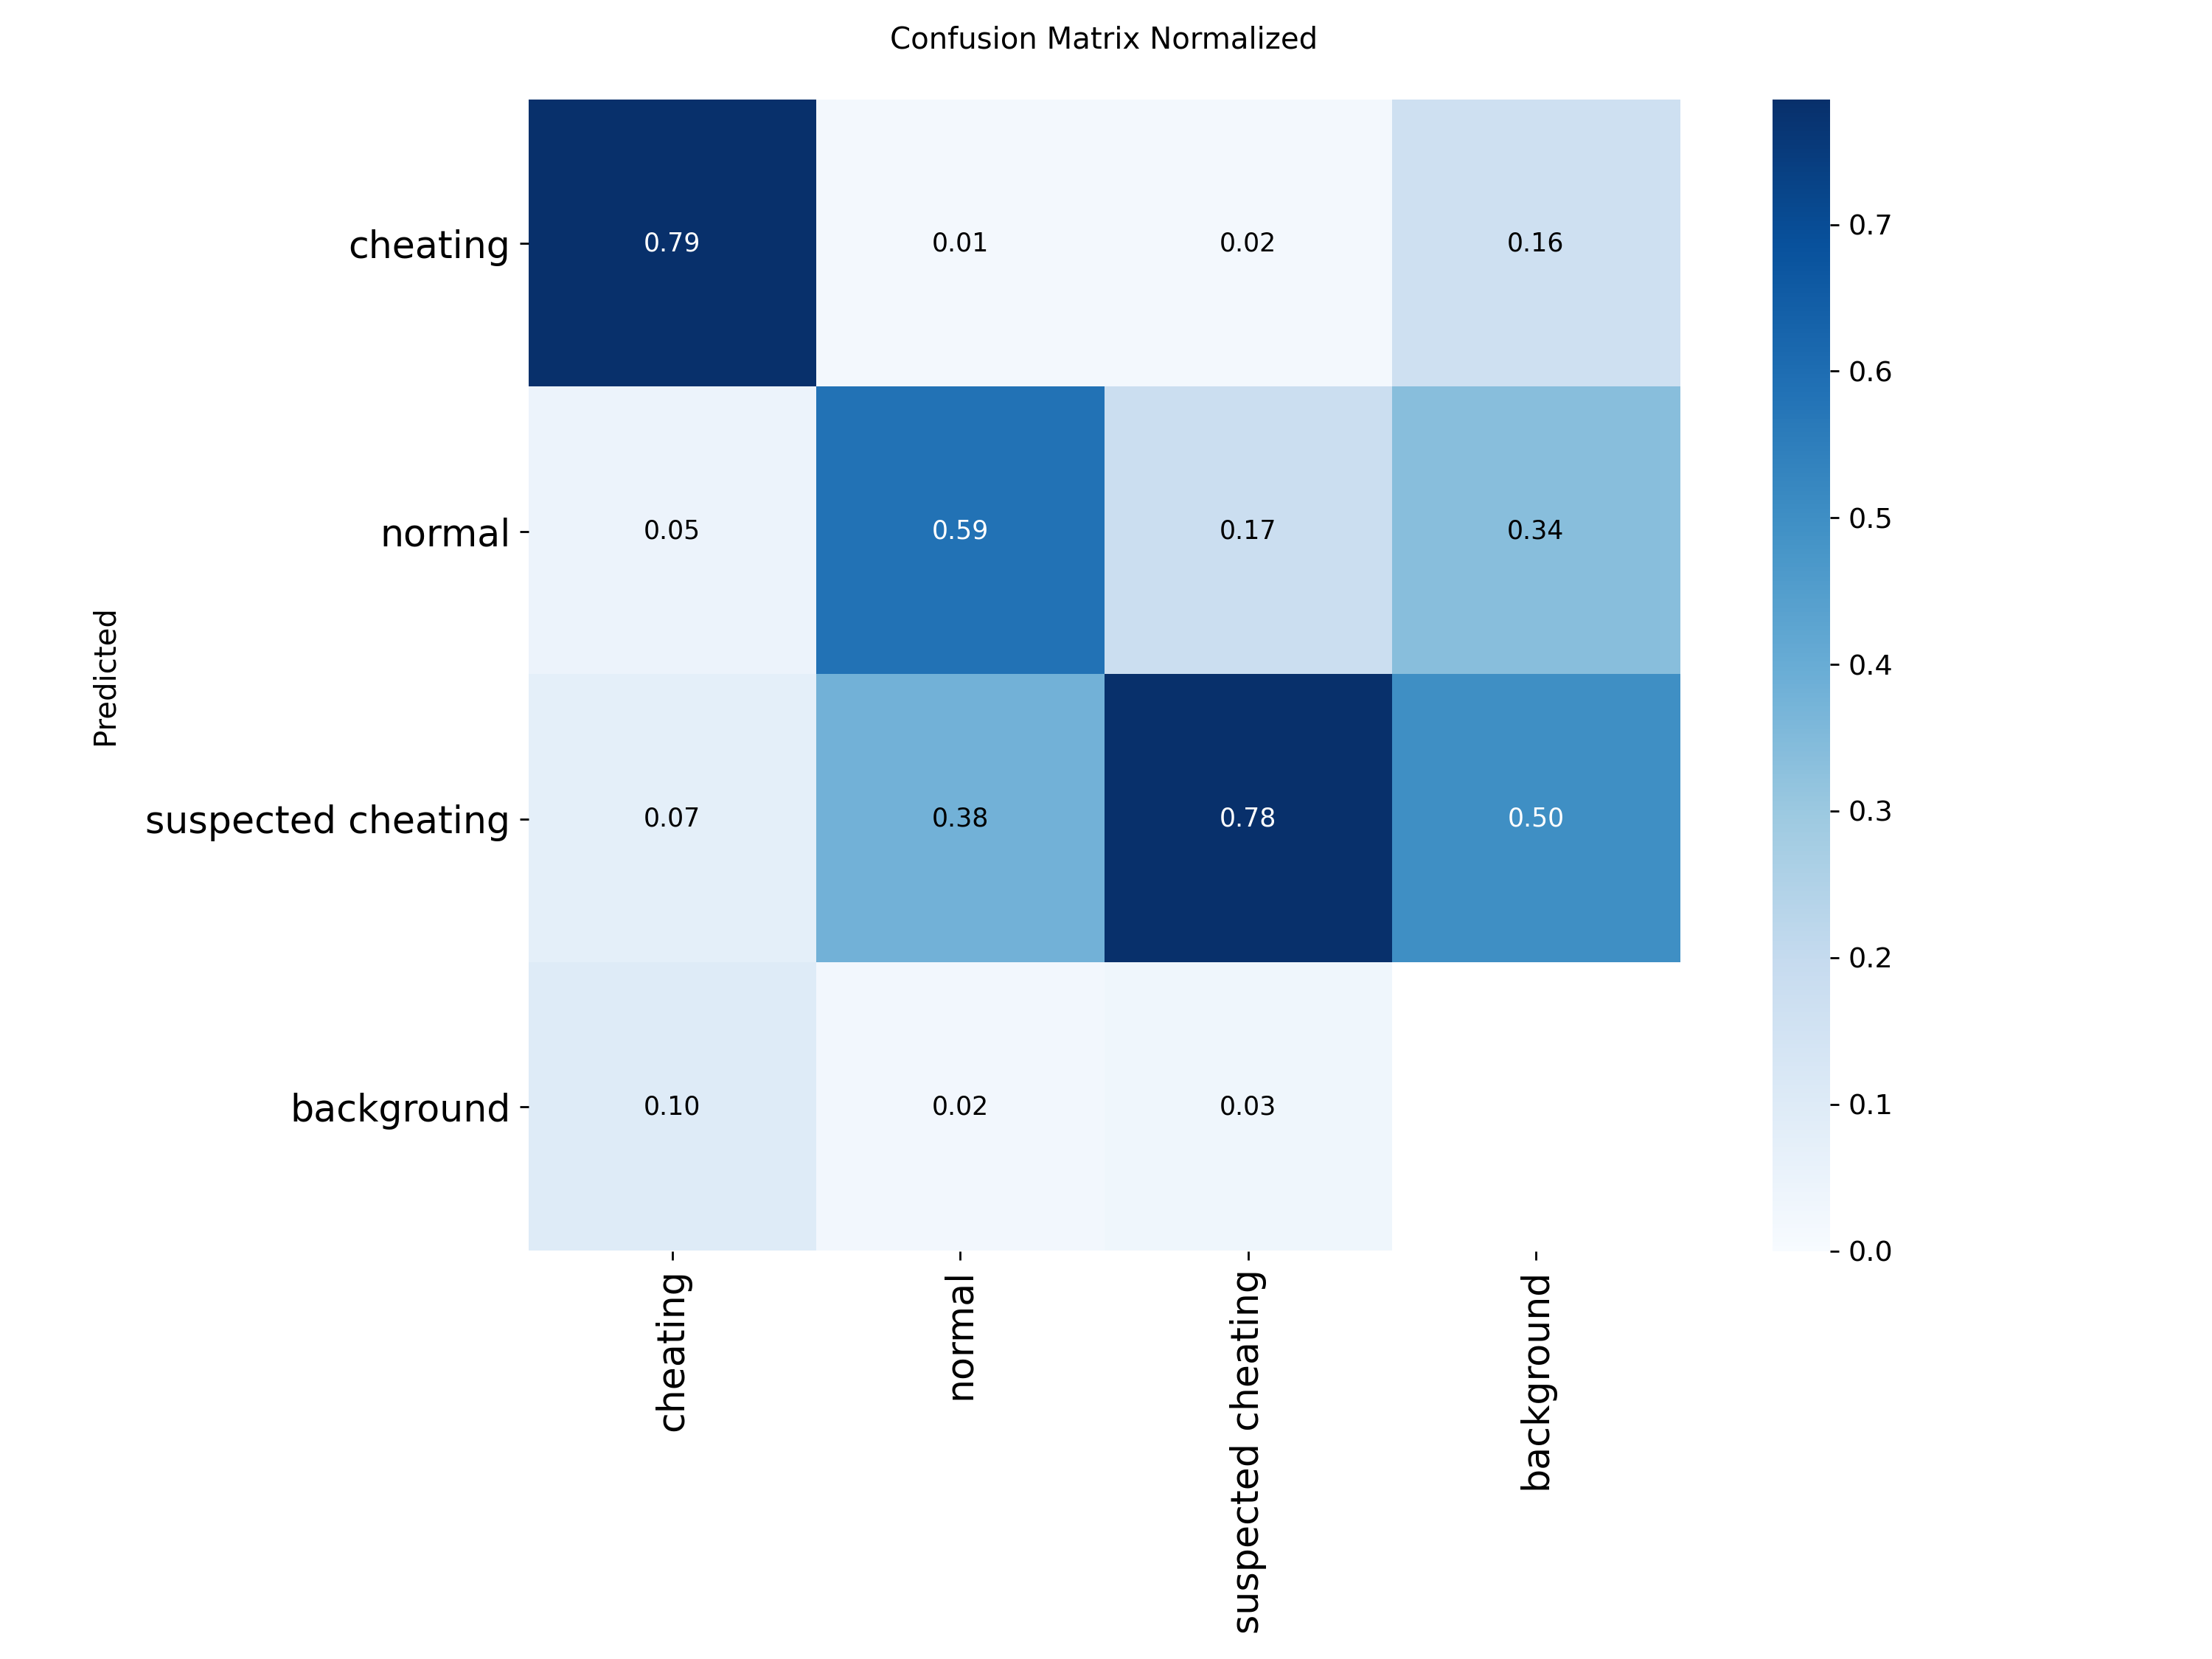

In [15]:
from IPython.display import Image as IPImage, display

for f in (RUNS / "train" / "results.png", RUNS / "eval" / "confusion_matrix_normalized.png"):
    if f.exists():
        display(IPImage(str(f)))

## 8. Quick visual check
A few test images with the trained model's predictions.

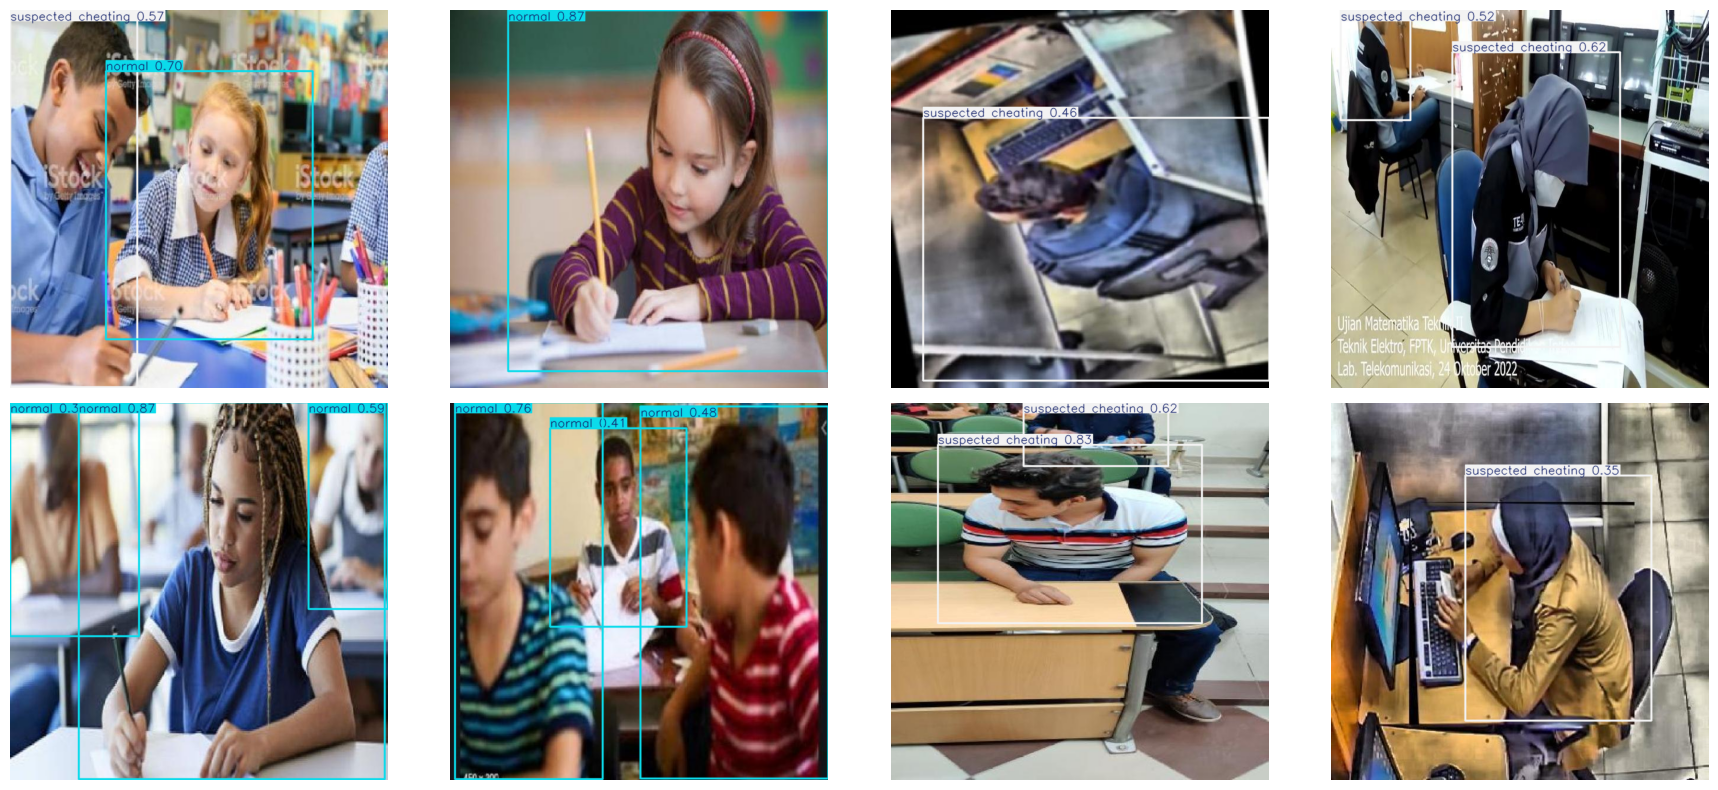

In [16]:
trained = YOLO(str(BEST))

test_dir = DATA_DIR / ("test" if (DATA_DIR / "test" / "images").exists() else "valid") / "images"

imgs = random.sample(sorted(test_dir.glob("*")), min(8, len(list(test_dir.glob("*")))))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, p in zip(axes.ravel(), imgs):
    r = trained.predict(str(p), imgsz=IMGSZ, conf=0.35, verbose=False, device=DEVICE)[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    ax.axis("off")

plt.tight_layout()
plt.show()

## 9. Export for the local Tkinter project
Creates `project_export/models/` with:
- `behavior_best.pt`: the model trained here
- `model_info.json`: class names, which classes are cheating, labels shown in alerts, image size
- `yolov8n-pose.pt`: pose + person tracking model (pretrained, COCO)

Copy the **contents of `models/`** into the local project's `models/` folder. The app merges `model_info.json`
into its `config.json` automatically.

In [17]:
EXPORT = WORK / "project_export"
(EXPORT / "models").mkdir(parents=True, exist_ok=True)

shutil.copy(BEST, EXPORT / "models" / "behavior_best.pt")

for name in ("yolov8n-pose.pt",):
    YOLO(name)                                   # triggers the download
    for cand in (Path(name), WORK / name, Path.home() / name):
        if cand.exists():
            shutil.copy(cand, EXPORT / "models" / name)
            break

model_info = {
    "models": {"behavior": "models/behavior_best.pt", "pose": "models/yolov8n-pose.pt"},
    "classes": {str(i): n for i, n in enumerate(CLASS_NAMES)},
    "cheating_classes": CHEATING_CLASSES,
    "behavior_labels": BEHAVIOR_LABELS,
    "class_kind": CLASS_KIND_OVERRIDE,
    "behavior_rules": BEHAVIOR_RULES,
    "imgsz": IMGSZ,
    "thresholds": {"behavior_conf": 0.35},
    "training": {"base_model": MODEL, "epochs": EPOCHS, "dataset": f"{RF_WORKSPACE}/{RF_PROJECT} v{RF_VERSION}", "test_metrics": summary},
}

(EXPORT / "models" / "model_info.json").write_text(json.dumps(model_info, indent=2, ensure_ascii=False))
(EXPORT / "results.json").write_text(json.dumps(summary, indent=2))

shutil.make_archive(str(WORK / "project_export"), "zip", EXPORT)

print(sorted(p.name for p in (EXPORT / "models").iterdir()))
print("Download: project_export.zip  (Output tab)")

['behavior_best.pt', 'model_info.json', 'yolov8n-pose.pt']
Download: project_export.zip  (Output tab)


## Next (local)
1. Unzip `project_export.zip` and copy everything inside `models/` into the local project's `models/` folder.
2. `python run_video.py your_video.mp4` to test, then `python main.py` for the desktop app.
3. Tune `behavior_conf`, `consecutive_frames`, and `phone_wrist_max_dist_ratio` in `config.json`.